In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [2]:
LOCAL_FILE = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
FALLBACK_URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

try:
    df = pd.read_csv(LOCAL_FILE)
    print("Loaded local file.")
except FileNotFoundError:
    df = pd.read_csv(FALLBACK_URL)
    print("Local file not found, loaded public copy instead.")

print("Shape:", df.shape)
df.head()

Local file not found, loaded public copy instead.
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [ ]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [ ]:
# All 11 rows have tenure = 0. They are brand-new customers who haven’t completed a billing cycle, so there are no charges yet. The blank is a real “nothing billed yet”, not a data error, which is why filling with 0 is justified. isnull() missed them because the blanks were whitespace strings, not NaN.
# Month-to-month contracts churn at 42.7%, versus 11.3% for one-year and 2.8% for two-year contracts.
# Fiber optic customers churn at 41.9%, versus 19.0% for DSL and 7.4% for no internet. Electronic check payers churn at 45.3%, versus roughly 15-19% for other payment methods.
# Customers without TechSupport churn at 41.6% (15.2% with it), and without OnlineSecurity at 41.8% (14.6% with it). Churners also have much shorter tenure (median 10 months versus 38 for stayers).

In [ ]:
print("Missing values per column (isnull):")
print(df.isnull().sum())

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("\nMissing values after conversion:")
print(df.isnull().sum()[df.isnull().sum() > 0])

df[df["TotalCharges"].isnull()][["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Missing values per column (isnull):
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Missing values after conversion:
TotalCharges    11
dtype: int64


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


Churn
No     5174
Yes    1869
Name: count, dtype: int64

Percentages:
Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64


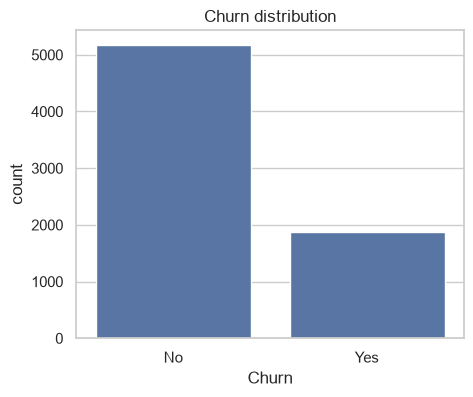

In [6]:
churn_counts = df["Churn"].value_counts()
print(churn_counts)
print("\nPercentages:")
print((df["Churn"].value_counts(normalize=True) * 100).round(1))

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x="Churn", ax=ax)
ax.set_title("Churn distribution")
plt.show()

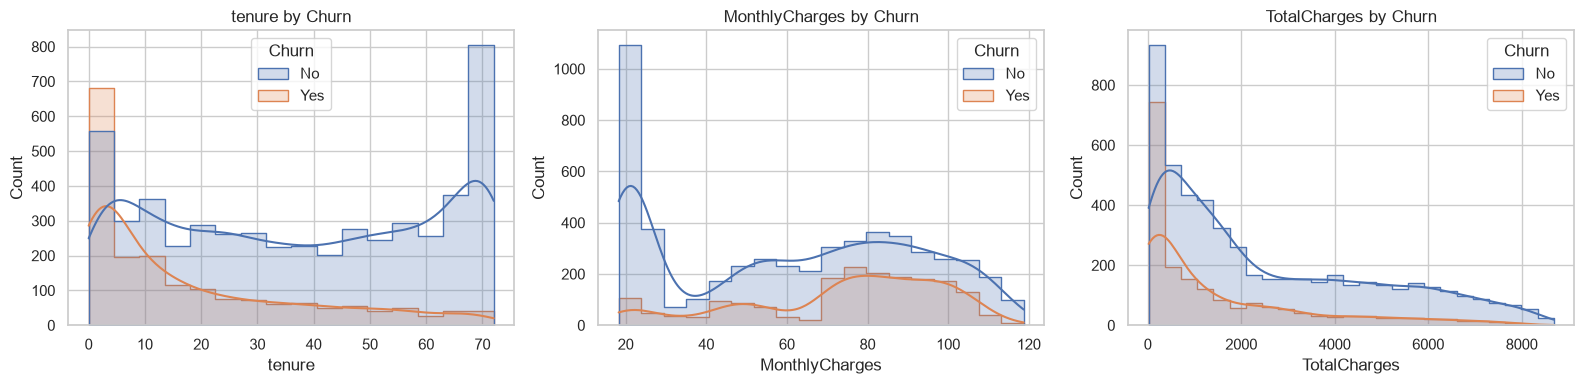

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.histplot(data=df, x=col, hue="Churn", kde=True, element="step", ax=ax)
    ax.set_title(f"{col} by Churn")

plt.tight_layout()
plt.savefig("fig_numeric_features.png", dpi=150)
plt.show()

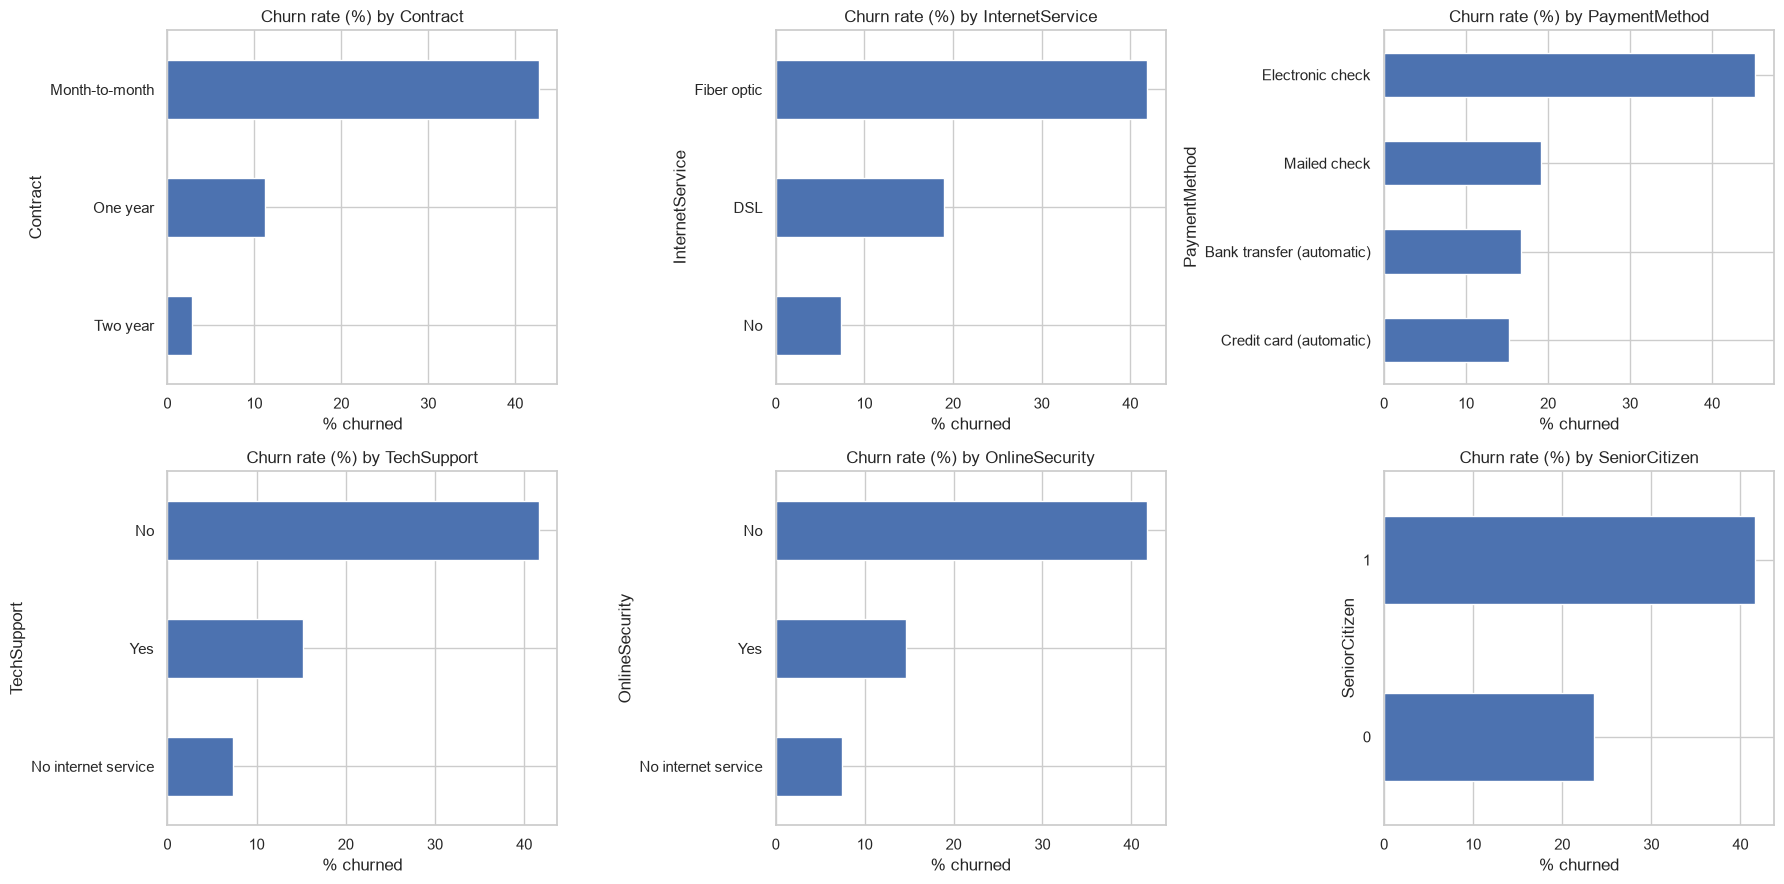

In [8]:
cat_cols_to_plot = ["Contract", "InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity", "SeniorCitizen"]

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.ravel(), cat_cols_to_plot):
    rate = df.groupby(col)["Churn"].apply(lambda s: (s == "Yes").mean() * 100)
    rate.sort_values().plot(kind="barh", ax=ax)
    ax.set_title(f"Churn rate (%) by {col}")
    ax.set_xlabel("% churned")

plt.tight_layout()
plt.savefig("fig_categorical_churn_rates.png", dpi=150)
plt.show()

In [9]:
data = df.copy()

data["TotalCharges"] = data["TotalCharges"].fillna(0)

data = data.drop(columns=["customerID"])

data["Churn"] = data["Churn"].map({"Yes": 1, "No": 0})

print("Missing values left:", data.isnull().sum().sum())
print("Target values:", data["Churn"].unique())

Missing values left: 0
Target values: [0 1]


In [10]:
service_cols = ["MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
                "TechSupport", "StreamingTV", "StreamingMovies"]
for col in service_cols:
    data[col] = data[col].replace({"No internet service": "No", "No phone service": "No"})

binary_cols = ["Partner", "Dependents", "PhoneService", "PaperlessBilling"] + service_cols
for col in binary_cols:
    data[col] = data[col].map({"Yes": 1, "No": 0})

data["gender"] = data["gender"].map({"Female": 0, "Male": 1})

multi_cols = ["InternetService", "Contract", "PaymentMethod"]
data = pd.get_dummies(data, columns=multi_cols, drop_first=True, dtype=int)

print("Remaining non-numeric columns:", list(data.select_dtypes(exclude="number").columns))
print("Shape after encoding:", data.shape)
data.head()

Remaining non-numeric columns: []
Shape after encoding: (7043, 24)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,InternetService_Fiber optic,InternetService_No,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,0,0,1,0,0,0,0,1,29.85,29.85,0,0,0,0,0,0,1,0
1,1,0,0,0,34,1,0,1,0,1,0,0,0,0,56.95,1889.50,0,0,0,1,0,0,0,1
2,1,0,0,0,2,1,0,1,1,0,0,0,0,1,53.85,108.15,1,0,0,0,0,0,0,1
3,1,0,0,0,45,0,0,1,0,1,1,0,0,0,42.30,1840.75,0,0,0,1,0,0,0,0
4,0,0,0,0,2,1,0,0,0,0,0,0,0,1,70.70,151.65,1,1,0,0,0,0,1,0


In [11]:
X = data.drop(columns=["Churn"])
y = data["Churn"]

print("X shape:", X.shape, "| y shape:", y.shape)
print("Feature columns:")
print(list(X.columns))

X shape: (7043, 23) | y shape: (7043,)
Feature columns:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges', 'InternetService_Fiber optic', 'InternetService_No', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate train: {:.3f} | test: {:.3f}".format(y_train.mean(), y_test.mean()))

Train: (5634, 23) | Test: (1409, 23)
Churn rate train: 0.265 | test: 0.265


In [13]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train means (should be ~0):", X_train_scaled.mean(axis=0).round(2)[:5], "...")

Train means (should be ~0): [ 0.  0. -0.  0. -0.] ...


In [14]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
print("Model trained:", knn)

Model trained: KNeighborsClassifier()


In [15]:
y_pred = knn.predict(X_test_scaled)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy : {acc:.3f}")
print(f"Precision: {prec:.3f}")
print(f"Recall   : {rec:.3f}")
print(f"F1-score : {f1:.3f}")
print("\nBaseline (always predict 'No'): {:.3f}".format(1 - y_test.mean()))

Accuracy : 0.747
Precision: 0.525
Recall   : 0.500
F1-score : 0.512

Baseline (always predict 'No'): 0.735


[[866 169]
 [187 187]]


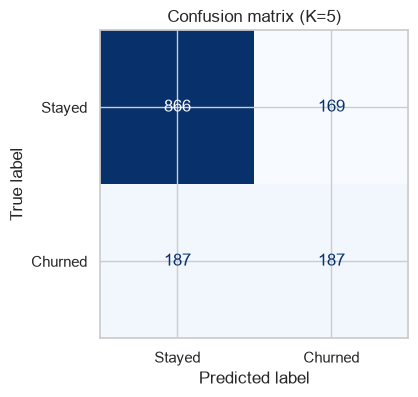

True negatives : 866  (correctly predicted stayed)
False positives: 169  (predicted churn, actually stayed)
False negatives: 187  (predicted stayed, actually churned) <- missed churners
True positives : 187  (correctly predicted churn)


In [16]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=["Stayed", "Churned"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion matrix (K=5)")
plt.savefig("fig_confusion_matrix_k5.png", dpi=150)
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True negatives : {tn}  (correctly predicted stayed)")
print(f"False positives: {fp}  (predicted churn, actually stayed)")
print(f"False negatives: {fn}  (predicted stayed, actually churned) <- missed churners")
print(f"True positives : {tp}  (correctly predicted churn)")

In [17]:
print(classification_report(y_test, y_pred, target_names=["Stayed", "Churned"]))

              precision    recall  f1-score   support

      Stayed       0.82      0.84      0.83      1035
     Churned       0.53      0.50      0.51       374

    accuracy                           0.75      1409
   macro avg       0.67      0.67      0.67      1409
weighted avg       0.74      0.75      0.75      1409



In [ ]:
# Accuracy is 74.7%, only about 1.2 points above the 73.5% baseline. That is barely better than guessing “No” for everyone.
# Recall for churners is 0.50. In plain English, the model catches about 50 out of every 100 customers who actually leave (187 of 374). Precision is 0.525, so about half of the customers it flags really do churn.
#A false negative is worse (187 here). A missed churner is lost revenue and gives the company no chance to intervene. A false positive (169) only means a retention offer, such as a discount, goes to someone who would have stayed. A save costs much less than a lost customer, so recall matters more than precision.